# Dynesty series: the retrievals against the linear prediction

`plot_dynesty.ipynb` shows one stored run in detail. This notebook reads **every** stored run and compares it with what the noiseless analysis predicts for it (`dynesty_utils.run_prediction`, theory in `Bias Analysis/Evidence_Prediction.ipynb`):

- the Bayes factor between the extended-source and the point-source model, $\ln B \approx \chi^2_{\min}/2 + \zeta\sqrt{\chi^2_{\min}}$, with $\chi^2_{\min}$ and the whitened residual $r_\perp$ from the noiseless $A_B$-only fit at the truth's own resolution and $\zeta = \hat r_\perp\cdot z$. In a simulation the standardised noise $z = (y_{\rm obs} - y_{\rm true})/\sigma$ is known exactly, so every run has its own prediction, without sampling;
- the posterior-median difference of $A_B$ between the two models on the same data, against the noiseless bias $\Delta A_B$;
- the posterior width of $A_B$ under the point-source model, against the Fisher $\sigma_{A_B}$.

The runs are grouped in `SERIES` (one pfrac per series; a run still in the queue is listed as missing and skipped, so re-run the notebook as the queue finishes). Runs whose difference from the baseline is not in the file name sit in subfolders of `dynesty_results/` (`null_test/`: point-source truth; `free_geometry/`: $a/R_\star$ and $R_p/R_\star$ sampled) and carry `subfolder=` in their entry; `series_table` checks each against its pickles.

The prediction applies to extended source vs point source only (equal parameter counts). Bayes factors against the point-source model with redistribution contain the Occam term of the $F$ prior and are tabulated as measured (section 5). Section 6 compares the special runs (three detectors, free geometry, null test, $A_B = 0.05$, 2 orbits) with their own predictions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from IPython.display import display
from dynesty_utils import *
from simple_bias_analysis import fit_truth   # the noiseless fits of the bias analysis, for the special runs of section 6
from HItargets_utils import PAPER_PLANETS, JWST_BANDS, detector_label, A_B_BOUNDS, A_B_FIT_BOUNDS
from paper_plot_utils import paper_figure, paper_theme

RESULTS_DIR = "dynesty_results"   # where run_dynesty.py saves; subfolders null_test/ and free_geometry/
N_JOBS = -1                       # the noiseless references and the rows run process-parallel (loky)
K_JITTER = 200                    # jittered realisations for the sampler error of ln B (0: analytic errors only)

In [2]:
# The series, as the keywords of find_dataset (planet, instrument, the settings that deviate from the baseline: seed 42, pfrac 0.8, A_B, n_bins, n_orbits of HItargets_utils).
JOINT, LRS = "JWST_NIRSpec.G395H_joint", "MIRI/LRS"
NRS1, NRS2 = JWST_BANDS[:2]
IMAGING = ("MIRI/F1280W", "MIRI/F1500W", "MIRI/F1800W")
THREE = (NRS1, NRS2, LRS)                      # one joint fit of the three detectors
T, K = "TOI-2431 b", "K2-141 b"

SERIES = {
    # --- noise realisations of the reference planets: one pfrac per series -----------------------------------------------------
    "TOI-2431 b joint (pfrac 0)":   [dict(planet=T, instrument=JOINT, seed=s, pfrac=0) for s in range(40, 50)],
    "TOI-2431 b LRS (pfrac 0.8)":   [dict(planet=T, instrument=LRS, seed=s) for s in range(40, 50)],
    "K2-141 b joint":               [dict(planet=K, instrument=JOINT, seed=s) for s in range(42, 47)],
    "K2-141 b LRS":                 [dict(planet=K, instrument=LRS, seed=s) for s in range(42, 47)],
    # --- seed 42: every paper planet in the two primary modes, and the single bands of the reference planets ----------------------
    "seed 42, nine planets":        [dict(planet=p, instrument=ins) for p in PAPER_PLANETS for ins in (JOINT, LRS)],
    "seed 42, single bands":        [dict(planet=T, instrument=ins) for ins in (NRS1, NRS2, *IMAGING)] + [dict(planet=K, instrument=ins) for ins in (NRS1, NRS2)],
    # --- TOI-2431 b, one setting changed at a time --------------------------------------------------------------------------------
    "TOI-2431 b, n_orbits 3 / 10":  [dict(planet=T, instrument=ins, n_orbits=n, **kw) for ins in (JOINT, LRS) for n, kw in ((3, {}), (10, {}), (10, dict(seed=43)))],
    "TOI-2431 b, n_bins 20 / 36":   [dict(planet=T, instrument=ins, n_bins=n) for ins in (JOINT, LRS) for n in (20, 36)],
    "TOI-2431 b, A_B = 0.4":        [dict(planet=T, instrument=ins, A_B=0.4) for ins in (JOINT, LRS)],
    # --- special runs (seed 43 and up) ---------------------------------------------------------------------------------------------
    "three detectors":              [dict(planet=p, instrument=THREE, seed=43) for p in (T, K)],
    "free geometry":                [dict(planet=p, instrument=ins, seed=43, subfolder="free_geometry") for p in (T, K) for ins in (JOINT, LRS)],
    "null test":                    [dict(planet=T, instrument=ins, seed=s, subfolder="null_test") for ins in (JOINT, LRS) for s in (43, 44, 45)],
    "TOI-2431 b, A_B = 0.05":       [dict(planet=T, instrument=ins, A_B=0.05, seed=43) for ins in (JOINT, LRS)],
    "TOI-2431 b LRS, 2 orbits":     [dict(planet=T, instrument=LRS, n_orbits=2, seed=s) for s in range(43, 48)],
    # --- the same data at another pfrac: NOT part of the series statistics above, only of the per-run checks and the pfrac comparison ---
    "TOI-2431 b joint (pfrac 1)":   [dict(planet=T, instrument=JOINT, seed=s, pfrac=1) for s in range(43, 47)],
    "TOI-2431 b LRS (other pfrac)": [dict(planet=T, instrument=LRS, seed=s, pfrac=p) for s, p in ((43, 0), (44, 0), (45, 1), (46, 1))],
}

# every stored run should be in a series: the stems on disk that no entry names
ALL = {f"{name} | {k}": kw for name, entries in SERIES.items() for k, kw in enumerate(entries)}
have = list_datasets(RESULTS_DIR)
on_disk = {os.path.join(sub, tag) if sub else tag for sub, tag in zip(have.subfolder, have.tag)}
listed = set()
for kw in ALL.values():
    try: listed.add(find_dataset(RESULTS_DIR, **kw))
    except FileNotFoundError: pass
print(f"{len(on_disk)} datasets in {RESULTS_DIR}/ (with subfolders), {len(listed)} of them in a series")
for stem in sorted(on_disk - listed): print(f"   run not in any series: {stem}")

67 datasets in dynesty_results/ (with subfolders), 67 of them in a series


## 1. The table: one row per run

`series_table` regenerates each configuration's noiseless truth once (the runs of one planet, mode and setting that differ only in seed and pfrac share it), fits the misspecified model to it at the truth's resolution, and evaluates every run against it. Each row asserts that $z$ reproduces the draws of `default_rng(seed)`, which also checks the regenerated truth; `z_dev` is the largest deviation. Missing and incomplete runs are listed below.

In [3]:
tab, missing = series_table(RESULTS_DIR, SERIES, K=K_JITTER, n_jobs=N_JOBS)
tab["mode"] = tab["instrument"].map(lambda ins: {JOINT: "joint NIRSpec", "joint-NRS1+NRS2+LRS": "NIRSpec + LRS", LRS: "MIRI/LRS"}.get(ins, detector_label(ins)))   # short labels: NRS1, NRS2, F1280W, ...
runs = tab.drop_duplicates("stem")   # a run can belong to two series (the seed-42 runs of the reference planets): every statistic over ALL runs uses each once

print(f"{len(runs)} runs evaluated ({len(tab)} series rows), {len(missing)} missing or incomplete:")
miss = pd.DataFrame([dict(series=name, **{k: (v if isinstance(v, (str, int, float)) else "+".join(x.split("_")[-1].split("/")[-1] for x in v)) for k, v in kw.items()}, reason=why) for name, kw, why in missing])
if len(miss): print(miss.fillna("").to_string(index=False))
stale = runs[runs["grid_change"] > 1e-6]
if len(stale): print(f"\nSTALE pickles (stellar grid changed since the run): {', '.join(stale['stem'])}")

67 runs evaluated (70 series rows), 24 missing or incomplete:
                    series     planet               instrument  seed reason     subfolder n_orbits
TOI-2431 b LRS (pfrac 0.8) TOI-2431 b                 MIRI/LRS    40 no run                       
TOI-2431 b LRS (pfrac 0.8) TOI-2431 b                 MIRI/LRS    41 no run                       
TOI-2431 b LRS (pfrac 0.8) TOI-2431 b                 MIRI/LRS    43 no run                       
TOI-2431 b LRS (pfrac 0.8) TOI-2431 b                 MIRI/LRS    44 no run                       
TOI-2431 b LRS (pfrac 0.8) TOI-2431 b                 MIRI/LRS    45 no run                       
TOI-2431 b LRS (pfrac 0.8) TOI-2431 b                 MIRI/LRS    46 no run                       
TOI-2431 b LRS (pfrac 0.8) TOI-2431 b                 MIRI/LRS    47 no run                       
TOI-2431 b LRS (pfrac 0.8) TOI-2431 b                 MIRI/LRS    48 no run                       
TOI-2431 b LRS (pfrac 0.8) TOI-2431 b          

## 2. Validation: $\zeta$ from the noise against $\zeta$ from the sampler

Two independent routes to the same number. $\zeta$ is the dot product $\hat r_\perp\cdot z$ of the noiseless residual with the simulated noise. $\zeta_{\rm inferred} = (2\,\Delta\ln\mathcal{L}_{\max} - \chi^2_{\min})/(2\sqrt{\chi^2_{\min}})$ uses only the sampler's best likelihoods; the table shows their difference. They agree where the linearisation holds and both models absorb the same directions; the sampler's finite resolution of $\ln\mathcal{L}_{\max}$ and the prior edge $A_B \geq 0$ (low-signal planets, $A_B = 0.05$) are the expected exceptions. `ΔH` is the difference in information between the two models: the Bayes factor follows the likelihood ratio only while it is small. `χ²_min / floor` is $\chi^2_{\min}$ over the numerical floor (the truth's own model at the injected parameters on the likelihood's grid against the truth curve) and must be large. `setting` names what a run changes from the baseline; `ln B` carries the sampler error from the jittered realisations.

What to look for: `ζ − ζ_inferred` small against the unit scatter of $\zeta$, for every run; the runs with the largest deviation are listed first. The lines below the table give the maxima and rms over the baseline-type runs and the largest deviation of the regenerated noise from `default_rng(seed)` (`z_dev`).

In [4]:
from HItargets_utils import DEFAULT_A_B, DEFAULT_N_BINS, DEFAULT_N_ORBITS

# Table helpers for sections 2 and 3: `setting` names what a run changes from the baseline of HItargets_utils (kind of run, A_B, n_bins, n_orbits) in one column instead of four
setting = lambda r: ", ".join(s for s, on in ((str(r["kind"]).replace("_", " "), r["kind"] != ""), (f"A_B = {r['A_B_true']:g}", r["A_B_true"] != DEFAULT_A_B),
                                                (f"{r['n_bins']:g} bins", r["n_bins"] != DEFAULT_N_BINS), (f"{r['n_orbits']:g} orbits", r["n_orbits"] != DEFAULT_N_ORBITS)) if on) or "baseline"
fmt = lambda f: (lambda v: "-" if pd.isna(v) else f.format(v))
pm = lambda m, s, f: "-" if pd.isna(m) else f.format(m) + ("" if pd.isna(s) else " ± " + f.format(s))   # value ± error (or ± sd), the ± only where defined

chk = runs.assign(dzeta=runs["zeta"] - runs["zeta_inferred"], dlnB=runs["lnB"] - runs["lnB_pred"])
chk = chk.reindex(chk["dzeta"].abs().sort_values(ascending=False).index)   # largest deviation first
display(pd.DataFrame({"planet": chk["planet"], "mode": chk["mode"], "setting": chk.apply(setting, axis=1), "seed": chk["seed"], "pfrac": chk["pfrac"].map(fmt("{:g}")),
                      "χ²_min": chk["chi2_min"].map(fmt("{:.2f}")), "χ²_min / floor": (chk["chi2_min"] / chk["chi2_floor"]).map(fmt("{:.0f}")),
                      "ζ": chk["zeta"].map(fmt("{:+.2f}")), "ζ − ζ_inferred": chk["dzeta"].map(fmt("{:+.3f}")), "prediction": chk["lnB_pred"].map(fmt("{:.2f}")),
                      "ln B": [pm(v, e, "{:.2f}") for v, e in zip(chk["lnB"], chk["lnB_err_jitter"])], "ln B − prediction": chk["dlnB"].map(fmt("{:+.2f}")),
                      "ΔH": chk["dH"].map(fmt("{:+.2f}"))}).style.hide(axis="index"))
base = chk[(chk["kind"] == "") & (chk["A_B_true"] >= 0.2)]
print(f"\nbaseline-type runs (hyperillumination truth, fixed geometry, A_B >= 0.2): max |zeta - zeta_inferred| = {base['dzeta'].abs().max():.3f}, rms {np.sqrt(np.mean(base['dzeta'] ** 2)):.3f};  "
      f"max |ln B - prediction| = {base['dlnB'].abs().max():.2f}, rms {np.sqrt(np.mean(base['dlnB'] ** 2)):.2f};  max |dH| = {base['dH'].abs().max():.2f};  max z_dev = {runs['z_dev'].max():.1e}")
print(f"chi2_min / chi2_floor >= {np.nanmin(runs['chi2_min'] / runs['chi2_floor']):.0f} in every run")

planet,mode,setting,seed,pfrac,χ²_min,χ²_min / floor,ζ,ζ − ζ_inferred,prediction,ln B,ln B − prediction,ΔH
TOI-2431 b,MIRI/LRS,A_B = 0.05,43,0.8,15.03,15430,-0.29,-0.283,6.37,8.04 ± 0.13,+1.67,-0.34
TOI-2431 b,F1800W,baseline,42,0.8,0.92,26192,-1.20,-0.062,-0.70,-0.57 ± 0.05,+0.13,-0.12
K2-141 b,MIRI/LRS,baseline,45,0.8,4.13,7841,+1.21,-0.058,4.53,5.00 ± 0.12,+0.47,-0.37
TOI-2431 b,joint NIRSpec,baseline,49,0,11.64,7048,-1.21,-0.055,1.68,1.72 ± 0.09,+0.03,+0.13
TOI-2431 b,joint NIRSpec,A_B = 0.05,43,0.8,14.78,7457,-0.15,-0.050,6.82,8.18 ± 0.18,+1.36,-0.83
Kepler-78 b,MIRI/LRS,baseline,42,0.8,0.16,4224,-1.28,-0.050,-0.43,-0.37 ± 0.09,+0.06,-0.06
Kepler-78 b,joint NIRSpec,baseline,42,0.8,0.30,1671,-0.55,-0.048,-0.15,-0.17 ± 0.16,-0.01,+0.02
TOI-2431 b,F1500W,baseline,42,0.8,1.81,24397,-1.21,-0.044,-0.72,-0.55 ± 0.06,+0.17,-0.12
TOI-2431 b,F1280W,baseline,42,0.8,1.78,22527,-1.21,-0.043,-0.72,-0.56 ± 0.07,+0.16,-0.11
K2-131 b,MIRI/LRS,baseline,42,0.8,0.37,6539,-1.22,-0.042,-0.56,-0.52 ± 0.07,+0.04,-0.06



baseline-type runs (hyperillumination truth, fixed geometry, A_B >= 0.2): max |zeta - zeta_inferred| = 0.062, rms 0.025;  max |ln B - prediction| = 0.47, rms 0.14;  max |dH| = 0.37;  max z_dev = 7.8e-15
chi2_min / chi2_floor >= 478 in every run


## 3. Series: measured against predicted

Two tables of the mean ± standard deviation over the runs of each series (`series_summary`; no ± for a single run). The first gives the measured $\ln B$ (extended source vs point source) next to the per-run prediction and to the noiseless expectation $\chi^2_{\min}/2$. The second gives the paired posterior-median difference of $A_B$ (misspecified model minus the truth's model, on the same data, so the noise largely cancels) next to the noiseless bias, and the posterior width against the Fisher $\sigma$. The individual runs follow.

What to look for: `ln B − prediction` scatters around zero with a spread far below that of `ln B`, i.e. the realisation-to-realisation scatter of $\ln B$ is explained by $\zeta$; the mean of `ζ` over a series of independent seeds is compatible with 0 within $1/\sqrt{n}$; `ΔA_B, posterior medians` reproduces `ΔA_B, noiseless`; `σ_post / σ_Fisher` is near 1 where the posterior is not cut by the prior (it drops below 1 for the low-signal planets, whose Fisher $\sigma$ is not small against the prior range).

In [5]:
# Series summary, split into ln B and A_B: mean ± sd over the runs of each series (no sd for a single run). The helpers are those of section 2.
summary = series_summary(tab)
both = lambda name, f="{:.2f}": [pm(m, s, f) for m, s in zip(summary[name], summary[name + " sd"])]
print("ln B, extended vs point source")
display(pd.DataFrame({"n": summary["n"], "seeds": summary["seeds"], "pfrac": summary["pfrac"], "ln B": both("lnB"), "prediction": both("lnB_pred"),
                      "χ²_min / 2": both("lnB_expected"), "ln B − prediction": both("lnB - pred"), "ζ": both("zeta"), "ζ − ζ_inferred": both("zeta - zeta_inferred", "{:.3f}")}))
print("A_B: paired posterior-median difference against the noiseless bias, posterior width against the Fisher sigma")
display(pd.DataFrame({"n": summary["n"], "ΔA_B, posterior medians": both("dA_median", "{:.4f}"), "ΔA_B, noiseless": both("dA_noiseless", "{:.4f}"),
                      "σ_post / σ_Fisher": both("sigma_post/sigma_F")}))

print("individual runs")
display(pd.DataFrame({"series": tab["series"], "planet": tab["planet"], "mode": tab["mode"], "setting": tab.apply(setting, axis=1), "seed": tab["seed"], "pfrac": tab["pfrac"].map(fmt("{:g}")),
                      "χ²_min / 2": tab["lnB_expected"].map(fmt("{:.2f}")), "ζ": tab["zeta"].map(fmt("{:+.2f}")), "prediction": tab["lnB_pred_ext_vs_ps"].map(fmt("{:.2f}")),
                      "ln B": [pm(v, e, "{:.2f}") for v, e in zip(tab["lnB_ext_vs_ps"], tab["lnB_err_jitter"])],
                      "ΔA_B, noiseless": tab["dA_noiseless"].map(fmt("{:+.4f}")), "ΔA_B, medians": tab["dA_median"].map(fmt("{:+.4f}")),
                      "σ_Fisher": tab["sigma_fisher"].map(fmt("{:.4f}")), "σ_post": tab["sigma_post"].map(fmt("{:.4f}")), "converged": tab["converged"]}).style.hide(axis="index"))

ln B, extended vs point source


,n,seeds,pfrac,ln B,prediction,χ²_min / 2,ln B − prediction,ζ,ζ − ζ_inferred
series,,,,,,,,,
TOI-2431 b joint (pfrac 0),10,"40,41,42,43,44,45,46,47,48,49",0,3.81 ± 1.62,3.85 ± 1.57,5.82 ± 0.00,-0.05 ± 0.11,-0.58 ± 0.46,-0.002 ± 0.024
TOI-2431 b LRS (pfrac 0.8),1,42,0.8,2.12,2.04,6.35,0.08,-1.21,-0.016
K2-141 b joint,5,"42,43,44,45,46",0.8,1.36 ± 0.52,1.50 ± 0.41,2.59 ± 0.00,-0.14 ± 0.15,-0.48 ± 0.18,0.002 ± 0.011
K2-141 b LRS,5,"42,43,44,45,46",0.8,1.86 ± 1.96,1.76 ± 1.79,2.07 ± 0.00,0.10 ± 0.27,-0.15 ± 0.88,-0.008 ± 0.035
"seed 42, nine planets",18,42,0.8,0.24 ± 1.30,0.25 ± 1.32,1.33 ± 1.88,-0.01 ± 0.07,-0.84 ± 0.42,-0.029 ± 0.010
"seed 42, single bands",7,42,0.8,-0.46 ± 0.38,-0.48 ± 0.38,1.52 ± 1.07,0.02 ± 0.13,-1.20 ± 0.01,-0.032 ± 0.018
"TOI-2431 b, n_orbits 3 / 10",6,"42,43",0.8,6.84 ± 4.50,6.87 ± 4.56,9.33 ± 4.42,-0.04 ± 0.11,-0.62 ± 0.47,-0.008 ± 0.011
"TOI-2431 b, n_bins 20 / 36",4,42,0.8,5.21 ± 3.56,5.22 ± 3.41,6.06 ± 0.31,-0.01 ± 0.17,-0.24 ± 0.99,-0.011 ± 0.015
"TOI-2431 b, A_B = 0.4",2,42,0.8,1.87 ± 1.22,1.90 ± 1.24,4.30 ± 0.63,-0.03 ± 0.02,-0.80 ± 0.58,-0.016 ± 0.001


A_B: paired posterior-median difference against the noiseless bias, posterior width against the Fisher sigma


,n,"ΔA_B, posterior medians","ΔA_B, noiseless",σ_post / σ_Fisher
series,,,,
TOI-2431 b joint (pfrac 0),10,-0.0444 ± 0.0016,-0.0418 ± 0.0000,1.00 ± 0.02
TOI-2431 b LRS (pfrac 0.8),1,-0.0659,-0.0588,0.98
K2-141 b joint,5,-0.0440 ± 0.0018,-0.0416 ± 0.0000,1.00 ± 0.02
K2-141 b LRS,5,-0.0508 ± 0.0114,-0.0626 ± 0.0000,0.81 ± 0.11
"seed 42, nine planets",18,-0.0336 ± 0.0141,-0.0326 ± 0.0132,0.89 ± 0.11
"seed 42, single bands",7,-0.0503 ± 0.0072,-0.0526 ± 0.0131,0.84 ± 0.19
"TOI-2431 b, n_orbits 3 / 10",6,-0.0536 ± 0.0119,-0.0503 ± 0.0093,0.99 ± 0.03
"TOI-2431 b, n_bins 20 / 36",4,-0.0521 ± 0.0103,-0.0496 ± 0.0096,0.99 ± 0.03
"TOI-2431 b, A_B = 0.4",2,-0.0386 ± 0.0125,-0.0364 ± 0.0095,0.98 ± 0.01


individual runs


series,planet,mode,setting,seed,pfrac,χ²_min / 2,ζ,prediction,ln B,"ΔA_B, noiseless","ΔA_B, medians",σ_Fisher,σ_post,converged
TOI-2431 b joint (pfrac 0),TOI-2431 b,joint NIRSpec,baseline,40,0,5.82,-0.11,5.44,5.61 ± 0.10,-0.0418,-0.0445,0.0265,0.0271,True
TOI-2431 b joint (pfrac 0),TOI-2431 b,joint NIRSpec,baseline,41,0,5.82,+0.11,6.18,6.17 ± 0.10,-0.0418,-0.0425,0.0265,0.0262,True
TOI-2431 b joint (pfrac 0),TOI-2431 b,joint NIRSpec,baseline,42,0,5.82,-0.41,4.41,4.42 ± 0.11,-0.0418,-0.0427,0.0265,0.0254,True
TOI-2431 b joint (pfrac 0),TOI-2431 b,joint NIRSpec,baseline,43,0,5.82,-0.15,5.31,5.22 ± 0.10,-0.0418,-0.0440,0.0265,0.0267,True
TOI-2431 b joint (pfrac 0),TOI-2431 b,joint NIRSpec,baseline,44,0,5.82,-0.48,4.18,4.08 ± 0.09,-0.0418,-0.0455,0.0265,0.0270,True
TOI-2431 b joint (pfrac 0),TOI-2431 b,joint NIRSpec,baseline,45,0,5.82,-0.56,3.91,3.88 ± 0.10,-0.0418,-0.0446,0.0265,0.0264,True
TOI-2431 b joint (pfrac 0),TOI-2431 b,joint NIRSpec,baseline,46,0,5.82,-0.72,3.36,3.25 ± 0.09,-0.0418,-0.0462,0.0265,0.0266,True
TOI-2431 b joint (pfrac 0),TOI-2431 b,joint NIRSpec,baseline,47,0,5.82,-1.12,2.00,1.93 ± 0.10,-0.0418,-0.0444,0.0265,0.0261,True
TOI-2431 b joint (pfrac 0),TOI-2431 b,joint NIRSpec,baseline,48,0,5.82,-1.10,2.05,1.78 ± 0.11,-0.0418,-0.0472,0.0265,0.0273,True
TOI-2431 b joint (pfrac 0),TOI-2431 b,joint NIRSpec,baseline,49,0,5.82,-1.21,1.68,1.72 ± 0.09,-0.0418,-0.0425,0.0265,0.0254,True


**Figure `ns_check`.** (a) the paired median difference against the noiseless bias, (b) the posterior width against the Fisher $\sigma$, (c) the measured against the predicted $\ln B$ with the sampler's error bars (jittered realisations). Dashed: one-to-one. Every stored run once; the marker groups separate the noise realisations of the reference planets, the other planets at seed 42, the runs with another number of orbits, and the remaining variations.

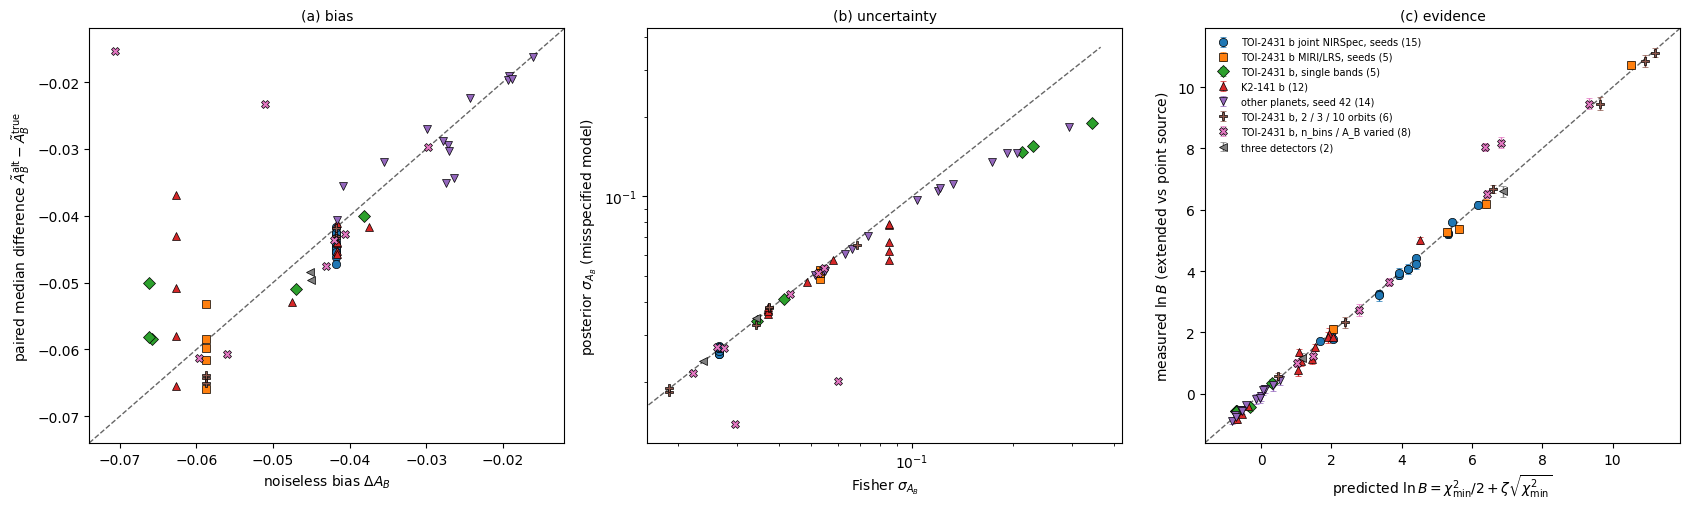

67 of 67 runs shown (null-test and free-geometry runs are compared with their own predictions in the last section)


In [6]:
PAPER_MODE = False
is_ = lambda name: (runs["series"] == name).to_numpy()
normal = (runs["kind"] == "").to_numpy()
ref_T = normal & (runs["planet"] == T).to_numpy() & (runs["n_orbits"] == 5).to_numpy() & (runs["n_bins"] == 27).to_numpy() & (runs["A_B_true"] == 0.2).to_numpy()
GROUPS = {"TOI-2431 b joint NIRSpec, seeds": ref_T & (runs["mode"] == "joint NIRSpec").to_numpy(),
          "TOI-2431 b MIRI/LRS, seeds": ref_T & (runs["mode"] == "MIRI/LRS").to_numpy(),
          "TOI-2431 b, single bands": ref_T & ~runs["mode"].isin(["joint NIRSpec", "MIRI/LRS", "NIRSpec + LRS"]).to_numpy(),
          "K2-141 b": normal & (runs["planet"] == K).to_numpy() & (runs["mode"] != "NIRSpec + LRS").to_numpy(),
          "other planets, seed 42": normal & ~runs["planet"].isin([T, K]).to_numpy(),
          "TOI-2431 b, 2 / 3 / 10 orbits": normal & (runs["planet"] == T).to_numpy() & (runs["n_orbits"] != 5).to_numpy(),
          "TOI-2431 b, n_bins / A_B varied": normal & (runs["planet"] == T).to_numpy() & (runs["n_orbits"] == 5).to_numpy() & ((runs["n_bins"] != 27) | (runs["A_B_true"] != 0.2)).to_numpy(),
          "three detectors": normal & (runs["mode"] == "NIRSpec + LRS").to_numpy()}
shown = np.any(list(GROUPS.values()), axis=0)
fig, axes = plot_ns_check(runs, groups=GROUPS)
paper_figure("ns_check", PAPER_MODE, fig=fig)
plt.show()
print(f"{int(shown.sum())} of {len(runs)} runs shown (null-test and free-geometry runs are compared with their own predictions in the last section)")

## 4. Same seed, other number of orbits

`simulate_data` draws the noise as $\sigma_{\rm bin}\,z$ from `default_rng(seed)`, so one seed gives the same $z$ for any number of orbits, and $\sigma_{\rm bin} \propto 1/\sqrt{n_{\rm orbits}}$. Runs of the same planet, mode and seed therefore share $\zeta$, and the likelihood-ratio statistic at $n$ orbits follows from the 5-orbit numbers alone:
$$2\,\Delta\ln\mathcal{L}_{\max}(n) = \tfrac{n}{5}\chi^2_{\min} + 2\zeta\sqrt{\tfrac{n}{5}\chi^2_{\min}} .$$
The cell pairs every run at another number of orbits with the baseline run of the same seed and compares the scaled prediction with the measured $2\,\Delta\ln\mathcal{L}_{\max}$ and $\ln B$.

What to look for: the shared $\zeta$ (the two `zeta` columns agree), and the scaled prediction against the measurement.

In [7]:
key = ["planet", "mode", "seed"]
five = runs[(runs["kind"] == "") & (runs["n_orbits"] == 5) & (runs["n_bins"] == 27) & (runs["A_B_true"] == 0.2)].sort_values("pfrac").drop_duplicates(key, keep="last").set_index(key)   # the pfrac 0.8 / 1 run where a seed has several
rows = []
for _, r in runs[(runs["kind"] == "") & (runs["n_orbits"] != 5)].iterrows():
    k = (r["planet"], r["mode"], r["seed"])
    if k not in five.index: rows.append(dict(planet=k[0], mode=k[1], seed=k[2], n_orbits=r["n_orbits"], note="no 5-orbit run of this seed")); continue
    b = five.loc[k]
    c = r["n_orbits"] / 5. * b["chi2_min"]
    rows.append(dict(planet=k[0], mode=k[1], seed=k[2], n_orbits=r["n_orbits"], zeta_5=b["zeta"], zeta_n=r["zeta"], dchi2_scaled=c + 2. * b["zeta"] * np.sqrt(c), dchi2_measured=2. * r["dlnL_max"],
                     lnB_scaled=0.5 * c + b["zeta"] * np.sqrt(c), lnB_measured=r["lnB"], lnB_err=r["lnB_err_jitter"]))
print(pd.DataFrame(rows).sort_values(["planet", "mode", "seed", "n_orbits"]).to_string(index=False, float_format=lambda v: f"{v:.3g}") if rows else "no run at another number of orbits yet")

    planet          mode  seed  n_orbits  zeta_5  zeta_n  dchi2_scaled  dchi2_measured  lnB_scaled  lnB_measured  lnB_err
TOI-2431 b      MIRI/LRS    42         3   -1.21   -1.21         0.942            1.05       0.471         0.566    0.112
TOI-2431 b      MIRI/LRS    42        10   -1.21   -1.21          13.2            13.3         6.6          6.69    0.133
TOI-2431 b      MIRI/LRS    43        10  -0.298  -0.298          22.4            22.3        11.2          11.1    0.143
TOI-2431 b joint NIRSpec    42         3  -0.413  -0.413           4.8            4.89         2.4          2.33    0.188
TOI-2431 b joint NIRSpec    42        10  -0.413  -0.413          19.3            19.4        9.65          9.46      0.2
TOI-2431 b joint NIRSpec    43        10  -0.149  -0.149          21.9            21.8        10.9          10.9    0.188


## 5. Measured only: the point-source model with redistribution, and the two pfrac

**Fits with redistribution.** For every run with a `naive_redist` fit: $\ln B$ of the truth's model against it, $\ln B$ of the point-source model with against without redistribution, and the posterior of $F$ (median, half-width of the 16-84 % interval, 95 % upper limit). No prediction: the prior of $F$ contributes an Occam term of about 3 nats and the posterior of $F$ is one-sided. The noiseless context ($\chi^2/2$ of that fit, the likelihood part) is in `Evidence_Prediction.ipynb`, section 2.

**pfrac.** Where the same data were sampled at two pfrac, the differences of $\ln B$ and of the $A_B$ posterior between the two runs, to judge whether the weighting of the sampler matters at the precision needed here.

In [8]:
red = runs[runs["lnB_vs_redist"].notna()]
cols = ["planet", "mode", "kind", "A_B_true", "n_bins", "n_orbits", "seed", "pfrac", "lnB_ext_vs_ps", "lnB_vs_redist", "lnB_redist_vs_ps", "F_med", "F_sigma", "F_95"]
print(red.assign(F_ratio=red["F_med"] / red["F_sigma"])[cols + ["F_ratio"]].sort_values(["kind", "planet", "mode", "A_B_true", "n_bins", "n_orbits", "seed", "pfrac"]).to_string(index=False, float_format=lambda v: f"{v:.3g}") if len(red) else "no run with a fit with redistribution")

# the same data (planet, mode, settings, seed) at two pfrac
same = ["planet", "mode", "kind", "A_B_true", "n_bins", "n_orbits", "seed"]
pairs = []
for k, g in runs.groupby(same):
    if g["pfrac"].nunique() < 2: continue
    g = g.sort_values("pfrac")
    a, b = g.iloc[0], g.iloc[-1]
    pairs.append(dict(zip(same, k), pfrac_a=a["pfrac"], pfrac_b=b["pfrac"], d_lnB=b["lnB"] - a["lnB"], d_lnB_vs_redist=b["lnB_vs_redist"] - a["lnB_vs_redist"],
                      d_A_B_med_ps=b["A_B_med_alt"] - a["A_B_med_alt"], d_sigma_post=b["sigma_post"] - a["sigma_post"]))
print("\nsame data at two pfrac (b - a):")
print(pd.DataFrame(pairs).drop(columns=["kind", "A_B_true", "n_bins", "n_orbits"]).to_string(index=False, float_format=lambda v: f"{v:.3g}") if pairs else "   no dataset sampled at two pfrac")

     planet          mode kind  A_B_true  n_bins  n_orbits  seed  pfrac  lnB_ext_vs_ps  lnB_vs_redist  lnB_redist_vs_ps   F_med  F_sigma    F_95  F_ratio
 HD 80653 b      MIRI/LRS            0.2      27         5    42    0.8         -0.752           4.16             -4.92 0.00221  0.00237 0.00828    0.933
 HD 80653 b joint NIRSpec            0.2      27         5    42    0.8          0.128           3.59             -3.46 0.00523  0.00465  0.0152     1.13
   K2-131 b      MIRI/LRS            0.2      27         5    42    0.8         -0.519           3.63             -4.15 0.00492  0.00576  0.0208    0.853
   K2-131 b joint NIRSpec            0.2      27         5    42    0.8          0.157            3.8             -3.64 0.00719  0.00634  0.0213     1.13
   K2-141 b      MIRI/LRS            0.2      27         5    42    0.8         -0.391           4.06             -4.45 0.00259  0.00214 0.00738     1.21
   K2-141 b      MIRI/LRS            0.2      27         5    43    0.8     

## 6. Special runs against their predictions

The runs that probe one assumption each, every one compared with a prediction made before sampling. They enter the table of section 1 through their series; this section adds what is specific to each. Runs that are still queued are listed as missing.

- **Three detectors** (NRS1 + NRS2 + MIRI/LRS in one fit). The per-run prediction is the same function, on the three-detector set. `chi2_bias_res` repeats the noiseless fit at the resolution of the bias analysis, the number of `Bias_Maps.ipynb` §1.5: the two $\chi^2_{\min}$ must agree up to the resolution difference seen for the single modes.
- **Free geometry** ($a/R_\star$, $R_p/R_\star$ and the inclination sampled with Gaussian priors in every model, in the parametrisation of the planet's source: $b$ for TOI-2431 b, with $i = \arccos[b/(a/R_\star)]$, and $i$ for K2-141 b). The prediction is the linear nuisance fit of `Nuisance_Robustness.ipynb` (row `+ all geometry`) at the truth's resolution, with the run's own priors read from its pickles: `chi2_min` and `sigma_fisher` are those of the marginalised fit (`chi2_min_fixed`, `sigma_fisher_fixed`: the fixed-geometry values), and $\zeta$ uses the augmented residual. `<name>_shrink` is the posterior width of a geometry parameter under the point-source model over its prior width, next to the linear prediction. A run that holds $i$ fixed (the design before 2026-11-11) is flagged if $a/R_\star$ comes out much narrower than its prior: the fixed inclination then pins the geometry, and the run understates $\sigma_{A_B}$ (relative to the row `+ all geometry` of the nuisance table, by 5–19 % for TOI-2431 b, depending on the mode, at $A_B$ = 0.2, 5 orbits).
- **Null test** (the data are drawn from the point-source model). Now the extended-source model is the misspecified one: $\ln B({\rm ext\ vs\ ps}) \approx -(\chi^2_{\rm null}/2 + \zeta'\sqrt{\chi^2_{\rm null}})$ with $\chi^2_{\rm null}$ and $r'$ from the noiseless fit of the extended-source model to the point-source truth. `dA_noiseless` is then the bias of the extended-source model, expected positive.
- **$A_B = 0.05$.** The noiseless point-source fit lies below $A_B = 0$, where the retrieval's prior ends, so the posterior piles up at the edge and the linear theory does not apply. The cell prints the prediction twice, from the unbounded noiseless fit (`A_B_FIT_BOUNDS`) and from the fit held at the floor (`A_B_BOUNDS`), next to the measurement, and the noiseless fits with redistribution for both ranges next to the posterior of $F$.
- **2 orbits.** The same seeds as 5-orbit runs, so each run is predicted from its 5-orbit partner by the scaling of section 4, which lists them.

What to look for: the measured $\ln B$ against `lnB_pred` in every block (the sign flips for the null test), and where the prediction is not expected to hold: the $A_B = 0.05$ runs, and any run whose point-source posterior touches $A_B = 0$.

In [9]:
SPECIAL = ["three detectors", "free geometry", "null test", "TOI-2431 b, A_B = 0.05", "TOI-2431 b LRS, 2 orbits"]
sp = tab[tab["series"].isin(SPECIAL)]
n_missing = {name: sum(1 for m in missing if m[0] == name) for name in SPECIAL}
print("special runs stored / still missing: " + ", ".join(f"{name}: {int((sp['series'] == name).sum())} / {n_missing[name]}" for name in SPECIAL))

cols = ["series", "planet", "mode", "n_orbits", "seed", "chi2_min", "lnB_expected", "zeta", "lnB_pred_ext_vs_ps", "lnB_ext_vs_ps", "lnB_err_jitter", "A_B_med_alt", "dA_noiseless", "dA_median", "sigma_fisher", "sigma_post"]
if len(sp):
    sgn = np.where(sp["truth"] == "hyperillum", 1., -1.)   # ln B in the orientation extended source vs point source: the expectation is -chi2_null / 2 for a null test
    print(sp.assign(lnB_expected=sgn * sp["lnB_expected"])[cols].to_string(index=False, float_format=lambda v: f"{v:.3g}"))
else:
    print("no special run stored yet")

# --- three detectors: the noiseless chi2_min again at the resolution of the bias analysis (Bias_Maps.ipynb 1.5)
for _, r in sp[sp["series"] == "three detectors"].iterrows():
    fits = load_fits(os.path.join(RESULTS_DIR, r["stem"] + "_*.pkl"))
    c2 = fit_naive(fits["naive"].meta["cfg"], [model_pcurve(c, "hyperillum", r["A_B_true"])[1] for c in fits["naive"].meta["cfg"]])[1]
    print(f"\nthree detectors, {r['planet']}: chi2_min = {r['chi2_min']:.3f} at the truth's resolution, {c2:.3f} at the resolution of the bias analysis (chi2_bias_res)")

# --- free geometry: marginalised against fixed-geometry prediction, and the shrinkage of the geometry priors
fg = sp[sp["series"] == "free geometry"]
if len(fg):
    print("\nfree geometry:")
    shrink = [f"{n}_{s}" for n in ("a_rs", "rp_rs", "b", "incl") for s in ("shrink", "shrink_pred") if f"{n}_{s}" in fg]   # the sampled geometry: b for TOI-2431 b, incl for K2-141 b
    print(fg[["planet", "mode", "seed", "chi2_min_fixed", "chi2_min", "sigma_fisher_fixed", "sigma_fisher", "sigma_post", *shrink, "A_B_med_alt", "A_B_med_truth"]].to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.3g}"))
    i_fixed = fg.filter(regex="^(b|incl)_shrink$").isna().all(axis=1)   # runs that sample neither b nor i
    pinned = fg[(fg["a_rs_shrink"] < 0.5) & i_fixed]
    if len(pinned): print("   a/R* posterior narrower than half its prior in " + ", ".join(f"{r['planet']} {r['mode']} ({r['a_rs_shrink']:.2f})" for _, r in pinned.iterrows()) + ": the fixed inclination pins the geometry (see the text above)")
    edge = fg[fg["A_B_med_alt"] - 2. * fg["sigma_post"] < 0.]
    if len(edge): print("   point-source posterior within 2 sigma of A_B = 0 (prior edge, the linear prediction is not expected to hold): " + ", ".join(f"{r['planet']} {r['mode']}" for _, r in edge.iterrows()))

# --- A_B = 0.05: the prediction from the noiseless fit held at the physical floor, and the noiseless fits with redistribution for both ranges (resolution of the bias analysis)
for _, r in sp[sp["series"] == "TOI-2431 b, A_B = 0.05"].iterrows():
    fits = load_fits(os.path.join(RESULTS_DIR, r["stem"] + "_*.pkl"))
    b = run_prediction(fits, ref=evidence_reference(fits, A_B_bounds=A_B_BOUNDS), K=0)
    print(f"\nA_B = 0.05, {r['planet']} {r['mode']} seed {r['seed']}: measured ln B = {r['lnB']:.2f} +- {r['lnB_err_jitter'] if np.isfinite(r['lnB_err_jitter']) else r['lnB_err']:.2f};  point-source posterior A_B = {r['A_B_med_alt']:.3f} +- {r['sigma_post']:.3f}")
    print(f"   unbounded noiseless fit: A_B = {r['A_B_true'] + r['dA_noiseless']:+.4f}, chi2_min = {r['chi2_min']:.2f}, predicted ln B = {r['lnB_pred']:.2f}  (measured - predicted {r['lnB'] - r['lnB_pred']:+.2f})")
    print(f"   held at A_B >= 0:        A_B = {b['A_B_true'] + b['dA_noiseless']:+.4f}, chi2_min = {b['chi2_min']:.2f}, predicted ln B = {b['lnB_pred']:.2f}  (measured - predicted {r['lnB'] - b['lnB_pred']:+.2f})")
    cfg_ = fits["naive"].meta["cfg"]
    for rng, lab in ((A_B_FIT_BOUNDS, "unbounded"), (A_B_BOUNDS, "A_B >= 0")):
        j = fit_truth(cfg_, r["A_B_true"], models=("naive_redist",), bounds=rng)["naive_redist"]
        print(f"   noiseless fit with redistribution, {lab:9s}: A_B = {j['A_B_fit']:+.4f}, F = {j['F_fit']:.4f}" + (f"   (posterior: F = {r['F_med']:.4f} +- {r['F_sigma']:.4f}, < {r['F_95']:.4f} at 95 %)" if "F_med" in r and np.isfinite(r["F_med"]) else ""))

special runs stored / still missing: three detectors: 2 / 0, free geometry: 0 / 4, null test: 0 / 6, TOI-2431 b, A_B = 0.05: 2 / 0, TOI-2431 b LRS, 2 orbits: 0 / 5
                series     planet          mode  n_orbits  seed  chi2_min  lnB_expected   zeta  lnB_pred_ext_vs_ps  lnB_ext_vs_ps  lnB_err_jitter  A_B_med_alt  dA_noiseless  dA_median  sigma_fisher  sigma_post
       three detectors TOI-2431 b NIRSpec + LRS         5    43      24.4          12.2  -1.08                6.88            6.6            0.19         0.14       -0.0452    -0.0485        0.0237       0.024
       three detectors   K2-141 b NIRSpec + LRS         5    43      9.36          4.68  -1.15                1.17           1.16           0.185        0.137       -0.0451    -0.0497        0.0341      0.0348
TOI-2431 b, A_B = 0.05 TOI-2431 b joint NIRSpec         5    43      14.8          7.39 -0.147                6.82           8.18           0.177       0.0144       -0.0511    -0.0232        0.0297      0.0